# From a trained model to a flood map

Training a model is usually the part with the tutorials. This notebook goes on to the next part:
saving the model with what inference needs, then running it over whole satellite tiles and
getting GeoTIFFs back.

We train a ManySeg U-Net on chips from [Sen1Floods11](https://github.com/cloudtostreet/Sen1Floods11)
(Bonafilia et al. 2020, CC BY 4.0), then point it at the Fitzroy River in Western Australia, which
had a record flood in January 2023. That flood isn't in the training data. We compare a tile
from about a week after the peak with the same tile in the dry season.

It downloads about 1.3 GB (chips and two tiles) and takes a couple of minutes on a GPU, plus the
downloads. Training is much slower on a CPU.

You need `pip install "manypred[geo]" manyseg matplotlib`.

In [1]:
import os
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from time import perf_counter
from urllib.request import urlopen, urlretrieve

import manyseg
import matplotlib.pyplot as plt
import numpy as np
import rasterio
import torch
import torch.nn.functional as F
from manyseg import create_model
from manyseg.losses import multiclass_dice
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from torch.utils.data import DataLoader, Dataset

from manypred import predict_batch, predict_files
from manypred.geo import stack_rasters

DATA = Path(os.environ.get("MANYPRED_DATA", "data"))  # downloads go here
SMOKE = os.environ.get("MANYPRED_NOTEBOOK_SMOKE") == "1"  # the test suite: a few chips, one epoch
N_TRAIN, EPOCHS = (4, 1) if SMOKE else (160, 40)
RESOLUTION, PATCH, OVERLAP = (160, 256, 64) if SMOKE else (10, 1024, 256)
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
rng = np.random.default_rng(0)
plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})

## Train on chips

The chips are 512 x 512 px with hand-drawn water labels. We keep five bands that matter for water
and that the tiles below also have: green, red, near infrared and two shortwave infrared. The
chips are top-of-atmosphere reflectance and the tiles are surface reflectance, so the model will
meet slightly different numbers later. That's a real gap, and we look at the result with it in
mind.

The Bolivia flood stays out of training, so we have a fair score at the end.

In [2]:
BUCKET = "https://storage.googleapis.com/sen1floods11/v1.1"
FOLDER = f"{BUCKET}/data/flood_events/HandLabeled"
ALL_BANDS = (
    "B01",
    "B02",
    "B03",
    "B04",
    "B05",
    "B06",
    "B07",
    "B08",
    "B8A",
    "B09",
    "B10",
    "B11",
    "B12",
)
BANDS = ("B03", "B04", "B8A", "B11", "B12")
KEEP = [ALL_BANDS.index(b) for b in BANDS]


def split_names(split):
    url = f"{BUCKET}/splits/flood_handlabeled/flood_{split}_data.csv"
    lines = urlopen(url).read().decode().split()
    return sorted(line.split("_S1Hand")[0] for line in lines)


def read_tif(name, kind):
    path = DATA / "sen1floods11" / kind / f"{name}_{kind}.tif"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{FOLDER}/{kind}/{name}_{kind}.tif", path)
    with rasterio.open(path) as src:
        return src.read().astype(np.float32)


def load_chips(names):
    """Raw digital numbers (N, 5, H, W), as in the tiles, and labels (N, H, W): 255 is no data."""
    with ThreadPoolExecutor(8) as pool:
        images = list(pool.map(lambda n: read_tif(n, "S2Hand")[KEEP], names))
        labels = list(pool.map(lambda n: read_tif(n, "LabelHand")[0], names))
    y = np.stack(labels)
    return np.nan_to_num(np.stack(images)), np.where(y < 0, 255, y).astype(np.int64)


train_names = sorted(rng.permutation(split_names("train"))[:N_TRAIN].tolist())
bolivia_names = split_names("bolivia")[: 2 if SMOKE else None]
train_x, train_y = load_chips(train_names)
bolivia_x, bolivia_y = load_chips(bolivia_names)
print(f"train {train_x.shape}, Bolivia {bolivia_x.shape}")

train (160, 5, 512, 512), Bolivia (15, 5, 512, 512)


In [3]:
mean = train_x.mean((0, 2, 3), keepdims=True)
std = train_x.std((0, 2, 3), keepdims=True) + 1e-6


class Crops(Dataset):
    def __init__(self, images, labels, size=256):
        self.images, self.labels, self.size = (images - mean) / std, labels, size

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        top, left = np.random.randint(0, self.images.shape[-1] - self.size + 1, 2)
        window = (..., slice(top, top + self.size), slice(left, left + self.size))
        x, y = self.images[i][window], self.labels[i][window]
        if np.random.rand() < 0.5:
            x, y = x[..., ::-1], y[..., ::-1]
        if np.random.rand() < 0.5:
            x, y = x[..., ::-1, :], y[..., ::-1, :]
        return torch.from_numpy(x.copy()), torch.from_numpy(y.copy())


model = create_model(
    backbone="resnet18" if SMOKE else "resnet34",
    pretrained=not SMOKE,
    in_channels=len(BANDS),
    num_classes=2,
).to(device)
np.random.seed(0)
loader = DataLoader(
    Crops(train_x, train_y), batch_size=2 if SMOKE else 8, shuffle=True, drop_last=not SMOKE
)
optimiser = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
schedule = torch.optim.lr_scheduler.OneCycleLR(
    optimiser, max_lr=1e-3, total_steps=EPOCHS * len(loader)
)
start = perf_counter()
model.train()
for _ in range(EPOCHS):
    total = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        with torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
            logits = model(images)
            loss = F.cross_entropy(logits, labels, ignore_index=255)
            loss = loss + multiclass_dice(logits, labels, ignore_index=255)
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
        schedule.step()
        total += loss.item()
print(f"{EPOCHS} epochs in {perf_counter() - start:.0f} s, final loss {total / len(loader):.3f}")

40 epochs in 23 s, final loss 0.243


## Save what inference needs

A model on its own can't be used correctly. Someone has to know how the inputs were scaled and
whether the outputs want a softmax, and usually that knowledge lives in a training script nobody
can find. `manyseg.save` stores it next to the weights, in the raw digital numbers a tile holds
on disk.

ManyPred reads all of that through the model's `tiling_spec()`, without importing ManySeg.

In [4]:
Path("runs").mkdir(exist_ok=True)
path = manyseg.save(
    model,
    "runs/flood_unet.safetensors",
    normalize=[{"type": "zscore", "mean": mean.ravel().tolist(), "std": std.ravel().tolist()}],
    activations={"logits": "softmax"},
    classes=["land", "water"],
    bands=list(BANDS),
)
del model
loaded = manyseg.load(path)
spec = loaded.tiling_spec()
print("activation:", {name: out.get("activation") for name, out in spec["outputs"].items()})
print("normalise: ", [step["type"] for step in spec["normalize"]])
print("patches are padded to a multiple of", spec["pad_multiple"])

activation: {'logits': 'softmax'}
normalise:  ['zscore']
patches are padded to a multiple of 32


## Chips: `predict_batch`

Note what's missing from this call. There's no `normalize=` and no `activation=`, because the model
carries both. `predict_batch` runs chips whole, several at a time, on a background pipeline.
This is the score on a flood the model hasn't seen. It's one flood and one seed, so treat it as a
sanity check and not a benchmark.

(15, 1, 512, 512) uint8, 23 chips/s
water IoU on Bolivia: 0.609


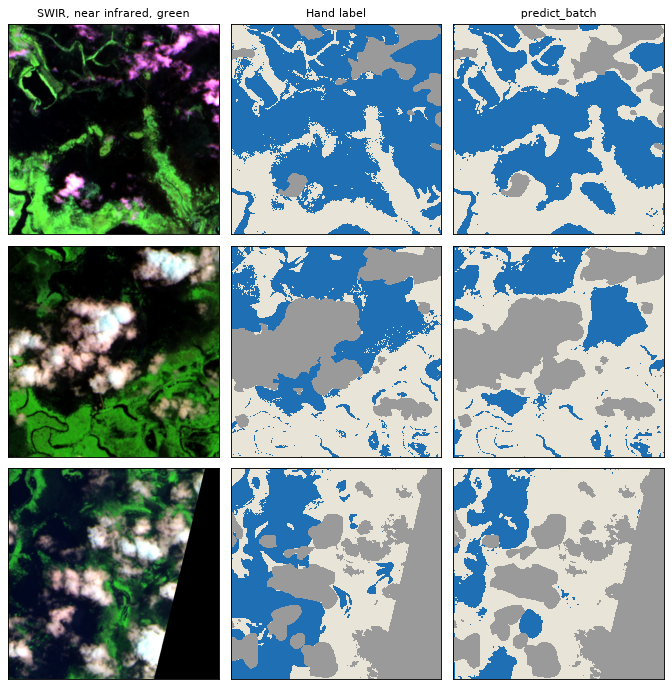

In [5]:
start = perf_counter()
chips = predict_batch(loaded, bolivia_x, batch_size=8, nodata=0, output="argmax", progress=False)
print(f"{chips.shape} {chips.dtype}, {len(chips) / (perf_counter() - start):.0f} chips/s")
valid = bolivia_y != 255
inter = ((chips[:, 0] == 1) & (bolivia_y == 1) & valid).sum()
union = (((chips[:, 0] == 1) | (bolivia_y == 1)) & valid).sum()
print(f"water IoU on Bolivia: {inter / union:.3f}")

order = np.argsort([-(y == 1).mean() for y in bolivia_y])[:3]
CHIP_COLOURS = ListedColormap(["#e8e4d8", "#1f6fb4", "#9a9a9a"])
fig, axes = plt.subplots(len(order), 3, figsize=(8.5, 2.9 * len(order)), squeeze=False)
for row, i in zip(axes, order, strict=True):
    rgb = bolivia_x[i][[4, 2, 0]].transpose(1, 2, 0)
    low, high = np.percentile(rgb, (2, 98), axis=(0, 1))
    row[0].imshow(np.clip((rgb - low) / np.maximum(high - low, 1), 0, 1))
    row[1].imshow(
        np.where(bolivia_y[i] == 255, 2, bolivia_y[i]),
        cmap=CHIP_COLOURS,
        vmin=0,
        vmax=2,
        interpolation="nearest",
    )
    row[2].imshow(
        np.where(bolivia_y[i] == 255, 2, chips[i, 0]),
        cmap=CHIP_COLOURS,
        vmin=0,
        vmax=2,
        interpolation="nearest",
    )
for ax, title in zip(
    axes[0], ("SWIR, near infrared, green", "Hand label", "predict_batch"), strict=True
):
    ax.set_title(title)
for ax in axes.flat:
    ax.set(xticks=[], yticks=[])
fig.tight_layout()

## Tiles: `predict_files`

A model trained on 256 px crops now runs over 10980 px tiles. `load_func` stacks each tile's five
files at 10 m, on a background thread. The default writer saves a GeoTIFF for each. There are
still no settings about the model here, only about the tiling.

In [6]:
BUCKET_S2 = "https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/51/K/YV"
SCENES = {
    "S2A_51KYV_20220929_0_L2A": "2022/9",  # 29 Sep 2022, dry season
    "S2B_51KYV_20230112_0_L2A": "2023/1",
}  # 12 Jan 2023, in flood


def band_path(scene, band):
    url = f"{BUCKET_S2}/{SCENES[scene]}/{scene}/{band}.tif"
    if SMOKE:  # read the file's overviews over the network instead of downloading it
        return url
    path = DATA / "s2" / scene / f"{band}.tif"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(url, path)
    return path


def load_scene(scene):
    return stack_rasters([band_path(scene, b) for b in BANDS], resolution=RESOLUTION)


start = perf_counter()
written = predict_files(
    loaded,
    list(SCENES),
    load_func=load_scene,
    output_dir=DATA / "flood_maps",
    patch_size=PATCH,
    overlap=OVERLAP,
    batch_size=4,
    nodata=0,
    output="argmax",
    progress=False,
)
print(f"{len(written)} tiles in {perf_counter() - start:.0f} s")
for path in written:
    print(path.name, f"{path.stat().st_size / 1e6:.0f} MB")

2 tiles in 14 s
S2A_51KYV_20220929_0_L2A_pred.tif 2 MB
S2B_51KYV_20230112_0_L2A_pred.tif 2 MB


## Did it find the flood?

The two tiles have different swath edges, so we compare only pixels with data in both. Each pixel
is 100 m².

In [7]:
def read_prediction(path):
    with rasterio.open(path) as src:
        return src.read(1), src.dataset_mask() > 0


(dry, dry_valid), (flood, flood_valid) = map(read_prediction, written)
both = dry_valid & flood_valid
km2 = (RESOLUTION / 1000) ** 2
for name, water in (("29 Sep 2022", dry), ("12 Jan 2023", flood)):
    print(f"{name}: {(water[both] == 1).sum() * km2:8.1f} km² of water")
print(f"compared over {both.sum() * km2:.0f} km²")

29 Sep 2022:      0.7 km² of water
12 Jan 2023:     47.6 km² of water
compared over 9447 km²


The model gives the flood tile far more water than the dry one, and it does so without any
flood-specific setting. Below, the river and its channels stand out in January. In September,
almost nothing does.

Read the map with some care. Each composite has its own colour stretch, so the colours aren't
comparable between dates. The flood tile has dark areas on the floodplain that the model doesn't
call water. They may be wet ground, flooded vegetation or burn scars, and this notebook can't tell
you which. And the model trained for under a minute on chips from other countries' floods.

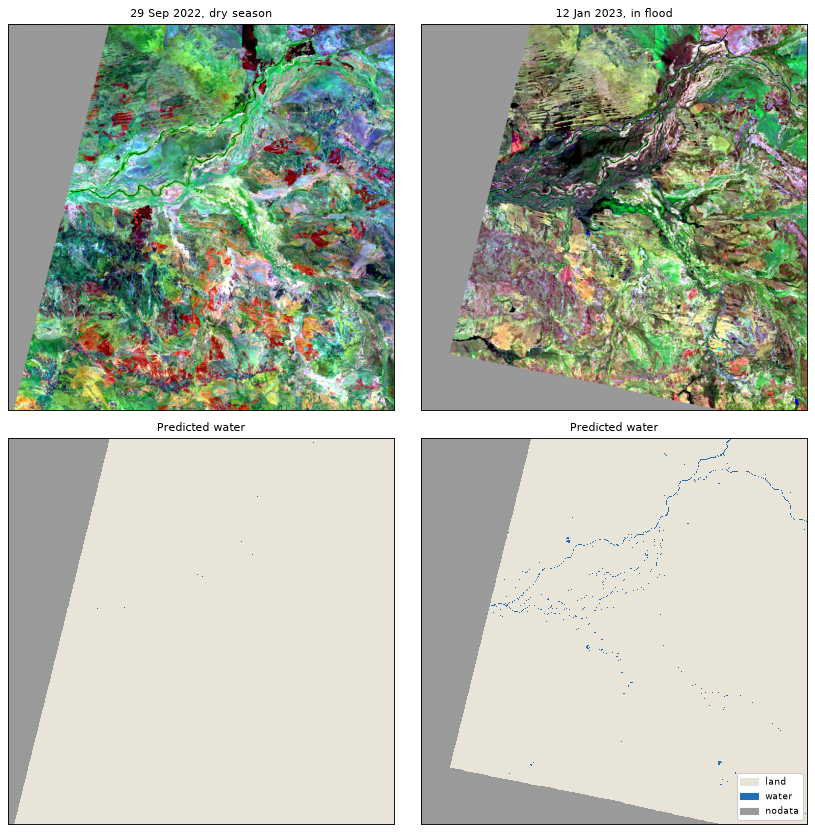

In [8]:
def composite(scene):
    """SWIR, near infrared, green from the file's overviews: water is close to black."""
    size = min(1000, 10980 * 10 // RESOLUTION)
    out = []
    for band in ("B12", "B8A", "B03"):
        with rasterio.open(band_path(scene, band)) as src:
            out.append(src.read(1, out_shape=(size, size)).astype(np.float32))
    rgb = np.stack(out, -1)
    valid = (rgb > 0).any(-1)
    low, high = np.percentile(rgb[valid], (2, 98), axis=0)
    rgb = np.clip((rgb - low) / np.maximum(high - low, 1), 0, 1)
    rgb[~valid] = 0.6
    return rgb


COLOURS = ["#e8e4d8", "#1f6fb4", "#9a9a9a"]
fig, axes = plt.subplots(2, 2, figsize=(10.5, 10.5))
for column, (scene, water, valid, title) in zip(
    axes.T,
    (
        (list(SCENES)[0], dry, dry_valid, "29 Sep 2022, dry season"),
        (list(SCENES)[1], flood, flood_valid, "12 Jan 2023, in flood"),
    ),
    strict=True,
):
    column[0].imshow(composite(scene))
    column[0].set_title(title)
    step = max(1, water.shape[0] // 1000)
    shown = np.where(valid, water, 2)[::step, ::step]
    column[1].imshow(shown, cmap=ListedColormap(COLOURS), vmin=0, vmax=2, interpolation="nearest")
    column[1].set_title("Predicted water")
for ax in axes.flat:
    ax.set(xticks=[], yticks=[])
axes[1, 1].legend(
    handles=[
        Patch(color=c, label=n) for c, n in zip(COLOURS, ("land", "water", "nodata"), strict=True)
    ],
    loc="lower right",
    fontsize=8,
    framealpha=1,
)
fig.tight_layout()

## Up close

The overview drops most pixels to fit the screen, so here is the part of the flood tile with the
most water, at full resolution.

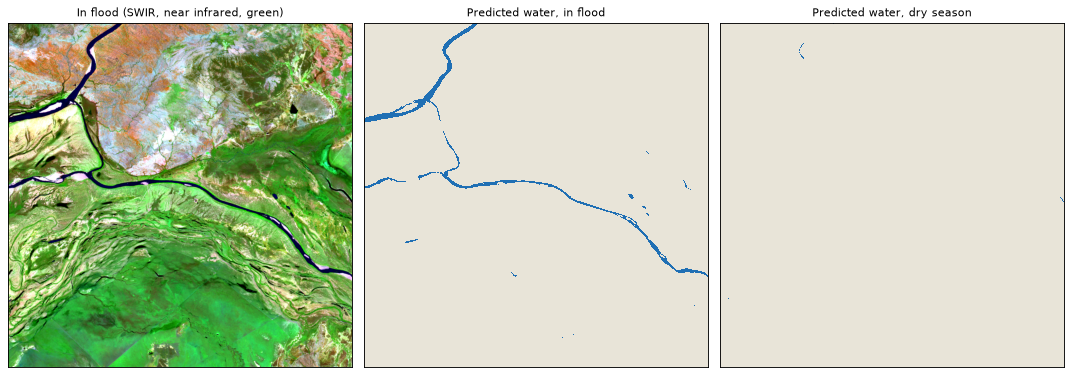

In [9]:
size = PATCH * 2
counts = {
    (r, c): (flood[r : r + size, c : c + size] == 1).sum()
    for r in range(0, flood.shape[0] - size + 1, size)
    for c in range(0, flood.shape[1] - size + 1, size)
    if both[r : r + size, c : c + size].mean() > 0.9
} or {(0, 0): 0}
top, left = max(counts, key=counts.get)


def crop_composite(scene):
    out = []
    for band in ("B12", "B8A", "B03"):
        with rasterio.open(band_path(scene, band)) as src:
            f = RESOLUTION / abs(src.transform.a)
            w = rasterio.windows.Window(left * f, top * f, size * f, size * f)
            out.append(src.read(1, window=w, out_shape=(size, size)).astype(np.float32))
    rgb = np.stack(out, -1)
    low, high = np.percentile(rgb, (2, 98), axis=(0, 1))
    return np.clip((rgb - low) / np.maximum(high - low, 1), 0, 1)


fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8))
crop = (slice(top, top + size), slice(left, left + size))
axes[0].imshow(crop_composite(list(SCENES)[1]))
axes[0].set_title("In flood (SWIR, near infrared, green)")
axes[1].imshow(
    flood[crop], cmap=ListedColormap(COLOURS[:2]), vmin=0, vmax=1, interpolation="nearest"
)
axes[1].set_title("Predicted water, in flood")
axes[2].imshow(dry[crop], cmap=ListedColormap(COLOURS[:2]), vmin=0, vmax=1, interpolation="nearest")
axes[2].set_title("Predicted water, dry season")
for ax in axes:
    ax.set(xticks=[], yticks=[])
fig.tight_layout()

## Where to go next

* Give the model more than one input and more than one output, in
  [the next notebook](03_two_grids_many_heads.ipynb).
* Turn these rasters into polygons, in [the block notebook](04_blocks_to_polygons.ipynb).
* Train properly. The [ManySeg notebooks](https://github.com/DPIRD-DMA/ManySeg/tree/main/notebooks)
  go further on training, and ManySeg's experiments compare the options.